# 05 · Segmentation: FCN, U-Net and Mask R-CNN

**Covers (Week 3 Key Concepts):** "Semantic Segmentation Architectures" (FCN, U-Net, encoder, decoder, skip connections) and "Mask R-CNN" (RPN, RoI Align, three outputs).
**Questions answered here:** Easy 19–20 · Medium 15–20 · Hard 7–9 · Mask R-CNN 1–8.

> **Semantic segmentation = give a class label to *every pixel* in an image.**

| | Output | Two touching cats → |
|---|---|---|
| Detection (notebook 04) | boxes + labels | two boxes |
| **Semantic segmentation** | a class for every pixel | one "cat" region (it doesn't separate individuals) |
| **Instance segmentation** (Mask R-CNN) | a separate mask for every object | cat #1 mask and cat #2 mask |

**The central challenge:** segmentation needs both **context** (*what* is this? which needs a big view of the image) and **precision** (*exactly where* is the boundary? which needs fine pixel detail). Classification only needs the first.

In [1]:
%matplotlib inline
import time
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.ops import roi_pool, roi_align

torch.manual_seed(0)
print("torch", torch.__version__)

torch 2.14.1+cu130


## 1 · A segmentation dataset: every pixel has a label

64×64 noisy images with circles, squares and triangles. The **mask** labels each pixel: 0 = background, 1 = circle, 2 = square, 3 = triangle. We get it for free by drawing each shape twice: once into the image and once (with its class number) into the mask.

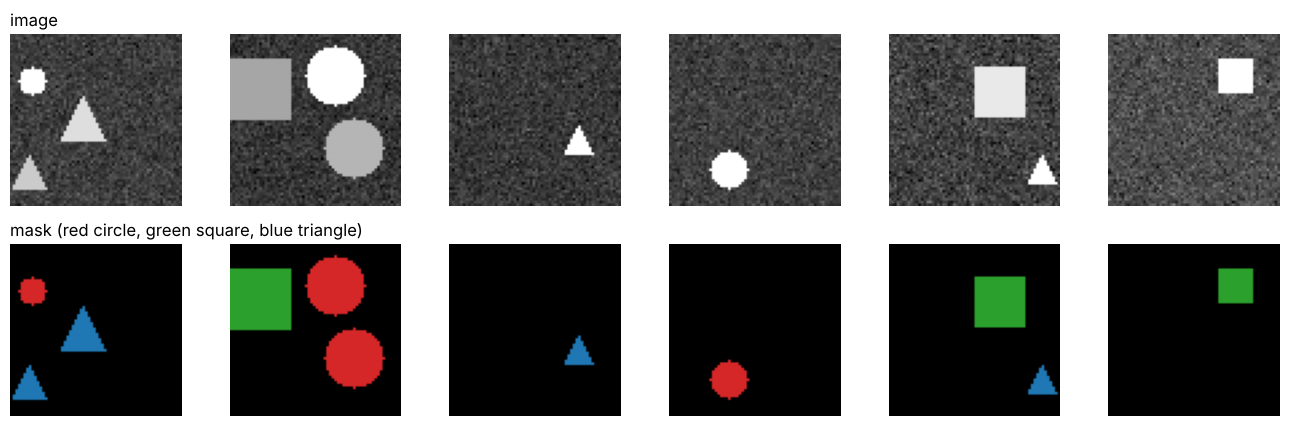

In [2]:
IMG = 64
NAMES = ["background", "circle", "square", "triangle"]

def draw(img, mask, cls, cx, cy, r, brightness):
    for target, value in [(img, brightness), (mask, cls + 1)]:
        if cls == 0:
            cv2.circle(target, (cx, cy), r, value, -1)
        elif cls == 1:
            cv2.rectangle(target, (cx - r, cy - r), (cx + r, cy + r), value, -1)
        else:
            cv2.fillPoly(target, [np.array([[cx, cy - r], [cx - r, cy + r], [cx + r, cy + r]], np.int32)], value)

def make_sample(rng):
    img = rng.normal(60, 15, (IMG, IMG)).clip(0, 255).astype(np.uint8)
    mask = np.zeros((IMG, IMG), np.uint8)
    for _ in range(rng.integers(1, 4)):
        r = int(rng.integers(5, 14)); cx = int(rng.integers(r, IMG - r)); cy = int(rng.integers(r, IMG - r))
        draw(img, mask, int(rng.integers(0, 3)), cx, cy, r, int(rng.integers(140, 255)))
    return img, mask

rng = np.random.default_rng(0)
train = [make_sample(rng) for _ in range(2000)]
test = [make_sample(rng) for _ in range(200)]
Xtr = torch.tensor(np.stack([a for a, _ in train]), dtype=torch.float32)[:, None] / 255
Ytr = torch.tensor(np.stack([b for _, b in train])).long()
Xte = torch.tensor(np.stack([a for a, _ in test]), dtype=torch.float32)[:, None] / 255
Yte = torch.tensor(np.stack([b for _, b in test])).long()

mask_cmap = plt.matplotlib.colors.ListedColormap(["black", "tab:red", "tab:green", "tab:blue"])
fig, ax = plt.subplots(2, 6, figsize=(13, 4.4))
for k in range(6):
    ax[0, k].imshow(train[k][0], cmap="gray"); ax[0, k].axis("off")
    ax[1, k].imshow(train[k][1], cmap=mask_cmap, vmin=0, vmax=3); ax[1, k].axis("off")
ax[0, 0].set_title("image", loc="left"); ax[1, 0].set_title("mask (red circle, green square, blue triangle)", loc="left")
plt.tight_layout(); plt.show()

## 2 · FCN: Fully Convolutional Network (2015)

**Problem solved:** classic CNNs end with **fully connected layers**. These flatten the feature maps into a vector, which **throws away *where* things are**, and they only accept one fixed input size.
**Innovation:** **replace the fully connected layers with convolutional layers.** Everything stays a 2-D map, so the output is a **dense, pixel-wise prediction map** (one class score per pixel), for any input size.
**Key idea:** end-to-end segmentation using convolutional layers only.

In [3]:
def conv_block(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
                         nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU())

class FCN(nn.Module):
    # encoder shrinks 64 -> 8 (x1/8); a 1x1 conv gives class scores; then simply stretch back x8
    def __init__(self, n_classes=4):
        super().__init__()
        self.enc1, self.enc2, self.enc3, self.bottom = conv_block(1, 16), conv_block(16, 32), conv_block(32, 64), conv_block(64, 64)
        self.classify = nn.Conv2d(64, n_classes, kernel_size=1)          # a conv instead of an FC layer
    def forward(self, x):
        x = self.enc1(x)
        x = self.enc2(F.max_pool2d(x, 2))
        x = self.enc3(F.max_pool2d(x, 2))
        x = self.bottom(F.max_pool2d(x, 2))                              # 8x8 map of rich "what" features
        return F.interpolate(self.classify(x), scale_factor=8, mode="bilinear", align_corners=False)

fcn = FCN()
for size in [64, 128]:
    out = fcn(torch.zeros(1, 1, size, size))
    print(f"input {size}x{size}  ->  output {tuple(out.shape)}   (4 class scores for every pixel)")

input 64x64  ->  output (1, 4, 64, 64)   (4 class scores for every pixel)
input 128x128  ->  output (1, 4, 128, 128)   (4 class scores for every pixel)


No `Flatten`, no `nn.Linear`. The same network accepts 64×64 *or* 128×128 images and returns a map of the same size. Use sizes divisible by 8 here, because each pooling step rounds odd sizes down.
**Weakness:** the prediction is made on an **8×8 map** and then blown up 8×. Each predicted value covers an 8×8-pixel block, so **predictions are coarse and boundaries blurry** (Medium Q17). Let's see that by training it.

In [4]:
def train_seg(model, epochs=6, lr=2e-3, batch=32):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), batch):
            idx = perm[i:i + batch]
            loss = F.cross_entropy(model(Xtr[idx]), Ytr[idx])      # cross-entropy computed at EVERY pixel
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        return model(Xte).argmax(1)

def mean_iou(pred, truth):
    ious = []
    for c in range(1, 4):
        inter = ((pred == c) & (truth == c)).sum().item(); union = ((pred == c) | (truth == c)).sum().item()
        if union:
            ious.append(inter / union)
    return float(np.mean(ious))

def boundary_accuracy(pred, truth):
    # accuracy measured ONLY on pixels lying on object edges - the hard part of segmentation
    edges = np.stack([cv2.morphologyEx((m > 0).astype(np.uint8), cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8))
                      for m in truth.numpy()]) > 0
    return (pred.numpy()[edges] == truth.numpy()[edges]).mean()

torch.manual_seed(0)
t = time.time()
fcn_pred = train_seg(FCN())
print(f"FCN trained in {time.time() - t:.0f} s:  mean IoU {mean_iou(fcn_pred, Yte):.3f},  "
      f"pixel accuracy {(fcn_pred == Yte).float().mean():.1%},  accuracy on boundary pixels {boundary_accuracy(fcn_pred, Yte):.1%}")

FCN trained in 24 s:  mean IoU 0.824,  pixel accuracy 97.9%,  accuracy on boundary pixels 77.2%


## 3 · U-Net (2015): encoder + decoder + skip connections

Designed for **biomedical images** (cells under a microscope), U-Net is now the standard in medical segmentation.

```
 ENCODER (downsampling path)                         DECODER (upsampling path)
 "what is it?" - context                             "where exactly?" - precision

 64x64 ──[conv]── e1 (16 ch) ═════ skip (copy) ═════════► concat ──[conv]── 64x64 ──► class per pixel
   │ pool                                                   ▲ up
 32x32 ──[conv]── e2 (32 ch) ═════ skip ═══════════► concat ──[conv]── 32x32
   │ pool                                             ▲ up
 16x16 ──[conv]── e3 (64 ch) ═════ skip ════► concat ──[conv]── 16x16
   │ pool                                      ▲ up
  8x8  ─────────[conv]──────── bottleneck ─────┘
```

- **Encoder (downsampling path):** conv + pooling **reduce the resolution** while building **context and high-level features** ("this region looks like a tumour"). It's like summarising a photo: you keep the big picture and lose fine detail.
- **Decoder (upsampling path):** **transposed convolutions** (learned upsampling) **recover the spatial resolution** to produce pixel-level predictions. It's like expanding the summary back to full size, but now with a label on every pixel.
- **Skip connections:** **copy** each encoder level's feature maps across and **concatenate** them with the decoder at the same resolution. This brings back the **fine edge details** that pooling threw away and combines **low-level detail** (edges, from early layers) with **high-level context** (meaning, from deep layers).

> **In short: the encoder compresses for context, the decoder reconstructs for precision, and skip connections bridge the two so no important detail is lost.**

In [5]:
class UNet(nn.Module):
    def __init__(self, n_classes=4):
        super().__init__()
        self.enc1, self.enc2, self.enc3, self.bottom = conv_block(1, 16), conv_block(16, 32), conv_block(32, 64), conv_block(64, 64)
        self.up3, self.dec3 = nn.ConvTranspose2d(64, 64, 2, stride=2), conv_block(64 + 64, 64)
        self.up2, self.dec2 = nn.ConvTranspose2d(64, 32, 2, stride=2), conv_block(32 + 32, 32)
        self.up1, self.dec1 = nn.ConvTranspose2d(32, 16, 2, stride=2), conv_block(16 + 16, 16)
        self.classify = nn.Conv2d(16, n_classes, 1)
    def forward(self, x):
        e1 = self.enc1(x)                                   # 64x64, fine detail
        e2 = self.enc2(F.max_pool2d(e1, 2))                 # 32x32
        e3 = self.enc3(F.max_pool2d(e2, 2))                 # 16x16
        b = self.bottom(F.max_pool2d(e3, 2))                # 8x8, most context
        d3 = self.dec3(torch.cat([self.up3(b), e3], dim=1))     # upsample + SKIP from e3
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))    # upsample + SKIP from e2
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))    # upsample + SKIP from e1
        return self.classify(d1)

# Transposed convolution = learned upsampling (doubles height and width here)
print("transposed conv:", tuple(nn.ConvTranspose2d(64, 32, 2, stride=2)(torch.zeros(1, 64, 8, 8)).shape), "<- from (1, 64, 8, 8)")

torch.manual_seed(0)
t = time.time()
unet_pred = train_seg(UNet())
print(f"U-Net trained in {time.time() - t:.0f} s:  mean IoU {mean_iou(unet_pred, Yte):.3f},  "
      f"pixel accuracy {(unet_pred == Yte).float().mean():.1%},  accuracy on boundary pixels {boundary_accuracy(unet_pred, Yte):.1%}")

transposed conv: (1, 32, 16, 16) <- from (1, 64, 8, 8)


U-Net trained in 63 s:  mean IoU 0.941,  pixel accuracy 99.6%,  accuracy on boundary pixels 99.2%


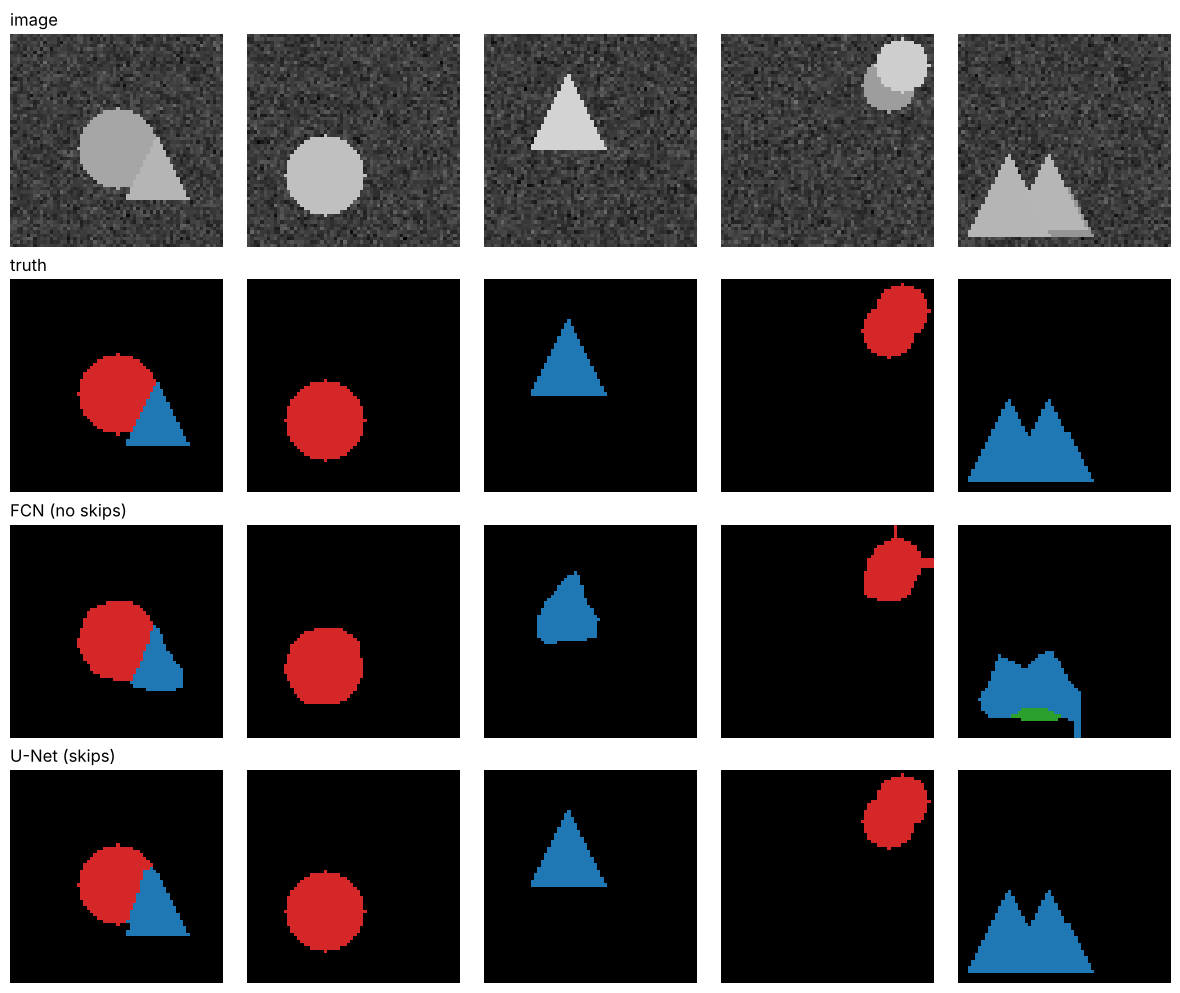

In [6]:
fig, ax = plt.subplots(4, 5, figsize=(12, 10))
for col, k in enumerate([0, 3, 7, 11, 15]):
    rows = [(Xte[k, 0], "gray", "image"), (Yte[k], mask_cmap, "truth"),
            (fcn_pred[k], mask_cmap, "FCN (no skips)"), (unet_pred[k], mask_cmap, "U-Net (skips)")]
    for row, (im, cmap, title) in enumerate(rows):
        ax[row, col].imshow(im, cmap=cmap, vmin=0, vmax=(1 if cmap == "gray" else 3))
        ax[row, col].axis("off")
        if col == 0:
            ax[row, col].set_title(title, loc="left")
plt.tight_layout(); plt.show()

**Look at the edges.** The FCN's shapes are blobby: corners are rounded off and triangles lose their points, because its decision was made at 1/8 resolution. The U-Net reproduces sharp corners. The *boundary-pixel accuracy* numbers above measure exactly this.

**Why skip connections help (Medium Q18, Hard Q8):** pooling discards *where* edges are, so the deepest layers know *what* but not *exactly where*. The skip connections hand the decoder the high-resolution feature maps from the encoder, so it can place each boundary precisely. The encoder supplies context, the skips supply precision, and the decoder combines both.

**Why U-Net is everywhere in medical imaging (Medium Q20):**
1. **Precise boundaries**, which you need to measure tumour size and plan surgery or radiotherapy.
2. **Small structures** (cells, lesions, vessels) survive thanks to the skip connections.
3. It **works with small datasets** (medical labels are expensive), helped by heavy augmentation.

**Satellite imagery (Hard Q9):** choose a **U-Net** (often with a pretrained ResNet or EfficientNet encoder). Roads, rivers and building outlines are thin structures with sharp boundaries that need pixel precision, and the encoder's context separates look-alike classes (roof vs road). Very large images are processed in overlapping tiles. Use **Mask R-CNN** instead if you need to count *individual* buildings or cars (instance segmentation).

## 4 · Mask R-CNN (2017): detection + a mask for every object

**Limitation it addresses (Q1):** detectors output only **boxes + labels**. Many applications need the **exact shape of each individual object**, i.e. **instance segmentation**. Semantic segmentation can't separate touching objects of the same class. Let's see that:

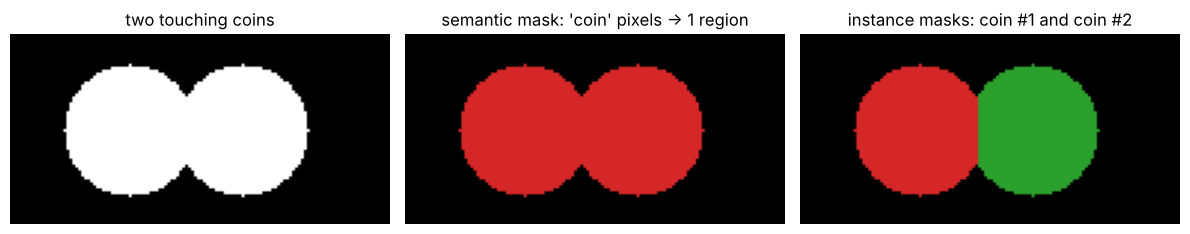

In [7]:
touching = np.zeros((64, 128), np.uint8)
cv2.circle(touching, (40, 32), 22, 1, -1)
cv2.circle(touching, (78, 32), 22, 1, -1)        # two circles that overlap/touch

n_regions, regions = cv2.connectedComponents(touching)
fig, ax = plt.subplots(1, 3, figsize=(12, 2.8))
ax[0].imshow(touching, cmap="gray"); ax[0].set_title("two touching coins")
ax[1].imshow(touching, cmap=mask_cmap, vmin=0, vmax=3); ax[1].set_title(f"semantic mask: 'coin' pixels -> {n_regions - 1} region")
inst = np.zeros_like(touching)
yy, xx = np.mgrid[:64, :128]
inst[(touching > 0) & ((xx - 40) ** 2 + (yy - 32) ** 2 <= (xx - 78) ** 2 + (yy - 32) ** 2)] = 1
inst[(touching > 0) & (inst == 0)] = 2
ax[2].imshow(inst, cmap=mask_cmap, vmin=0, vmax=3); ax[2].set_title("instance masks: coin #1 and coin #2")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### Architecture: Faster R-CNN + a mask branch

**Base:** Faster R-CNN (a detector). **Extension:** a **segmentation mask branch** for every Region of Interest (RoI).

How it works, step by step:
1. **Backbone** (e.g. ResNet-50 + FPN): computes feature maps of the whole image once.
2. **Region Proposal Network (RPN)** (Q3): a small network that slides over the feature map and **suggests candidate object regions** ("something might be here"), with objectness scores. It replaces the slow selective search of R-CNN.
3. **RoI Align** (Q4): cuts out a fixed-size feature patch (e.g. 7×7) for each proposal, **precisely**, without rounding coordinates (see the demo below).
4. **Classification + bounding-box regression:** what object is it, plus a refined box.
5. **Mask branch:** a small FCN that predicts a **binary mask** (e.g. 28×28) inside each box. It runs in parallel with step 4.

**Three outputs per object (Q5): ① a bounding box ② a class label ③ a pixel-level mask.**

### Why RoI Align? (Q4)
Proposal boxes have **fractional** coordinates on the feature map (a box from x = 1.3 to 3.7). The older **RoI Pooling** **rounds** them to whole cells (1 to 4), so the extracted features are slightly **misaligned** with the object. For boxes that hardly matters, but for **pixel-accurate masks** a shift of half a feature cell becomes many pixels in the image (each cell might cover 16 pixels). **RoI Align** removes the rounding: it **samples the feature map exactly at the fractional positions using bilinear interpolation**. Let's see the difference:

In [8]:
# A feature map whose value at every position = its x coordinate (0, 1, 2, ... 7), so misalignment is easy to read
fmap = torch.arange(8, dtype=torch.float32).repeat(8, 1)[None, None]   # (1, 1, 8, 8)
box = torch.tensor([[0, 1.3, 1.3, 3.7, 3.7]])                           # (batch index, x1, y1, x2, y2) - fractional!

pooled = roi_pool(fmap, box, output_size=(1, 4), spatial_scale=1.0)
# aligned=False: our toy map stores each value AT its whole-number coordinate (x=0,1,2,...)
aligned = roi_align(fmap, box, output_size=(1, 4), spatial_scale=1.0, sampling_ratio=2, aligned=False)

# What the 4 output columns SHOULD contain: the x positions at the centres of 4 equal slices of 1.3 .. 3.7
exact = [1.3 + (i + 0.5) * (3.7 - 1.3) / 4 for i in range(4)]
print("ideal values            :", np.round(exact, 2))
print("RoI Pool  (rounds box)  :", pooled[0, 0, 0].numpy(), "<- snapped to whole cells")
print("RoI Align (bilinear)    :", aligned[0, 0, 0].numpy().round(2), "<- follows the true box")

ideal values            : [1.6 2.2 2.8 3.4]
RoI Pool  (rounds box)  : [1. 2. 3. 4.] <- snapped to whole cells
RoI Align (bilinear)    : [1.6 2.2 2.8 3.4] <- follows the true box


RoI Pool's values are snapped to whole feature cells (and taking the max inside each bin biases them further). RoI Align reproduces the ideal values exactly, because it samples where the true box is. For segmentation masks this misalignment translates directly into shifted mask edges. RoI Align improved mask accuracy noticeably in the paper.

### Applications (Q7)
- **Medical imaging:** tumour segmentation, organ boundaries.
- **Autonomous driving:** pedestrians, vehicles and lane markings with precise shapes.
- **Crowd analysis:** separating overlapping people in dense scenes.
- **Others:** robotics grasping (exact object outline), photo editing (cut out a person), retail shelf analysis, agriculture (individual fruit or leaves).

### Overlapping objects in crowded scenes (Q8)
Mask R-CNN treats each object as its own **proposal (RoI)**. Each RoI gets its own class and **its own mask**, predicted only inside its box. Two overlapping people become two RoIs with two separate masks, even where they touch. NMS removes duplicate proposals. Each mask is a binary *this object / not this object* prediction per RoI, so masks of different objects don't compete with each other.

### Why pixel masks beat boxes in medical imaging (Q6)
1. **Precise localization:** tumours and organs have irregular shapes, and a box includes lots of healthy tissue.
2. **Quantitative analysis:** masks give the true **size, area and volume**, while boxes overestimate them (e.g. tumour volume for chemotherapy dosing).
3. **Clinical decisions:** surgery and radiotherapy need the exact border and how it spreads.
4. **Overlaps:** a tumour inside an organ can't be separated by boxes, but masks can.

> **Key insight:** boxes say *"there's a tumour here"*; masks say *exactly which pixels are tumour*.

## 5 · Optional: a real pretrained Mask R-CNN on your photo
Downloads about 170 MB of weights the first time. Set `RUN = True` on your own machine.

In [9]:
RUN = False
IMAGE_PATH = "../../week-1/code/sample.jpg"

if RUN:
    from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
    weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
    model = maskrcnn_resnet50_fpn(weights=weights).eval()
    photo = cv2.cvtColor(cv2.imread(IMAGE_PATH), cv2.COLOR_BGR2RGB)
    with torch.no_grad():
        out = model([torch.tensor(photo).permute(2, 0, 1).float() / 255])[0]
    overlay = photo.copy()
    for mask, label, score in zip(out["masks"], out["labels"], out["scores"]):
        if score > 0.6:
            colour = np.random.randint(0, 255, 3)
            overlay[mask[0].numpy() > 0.5] = (0.5 * overlay[mask[0].numpy() > 0.5] + 0.5 * colour).astype(np.uint8)
            print(f"{weights.meta['categories'][label]:<12} score {score:.2f}")
    plt.figure(figsize=(10, 6)); plt.imshow(overlay); plt.axis("off"); plt.show()
else:
    print("Skipped. Set RUN = True to download and run a pretrained Mask R-CNN.")

Skipped. Set RUN = True to download and run a pretrained Mask R-CNN.


---
## Key takeaways
- **FCN:** the first step. Replacing FC layers with conv layers proved CNNs can do segmentation, but predictions are **coarse**.
- **U-Net:** improved precision with an **encoder–decoder + skip connections**, and became the standard in medical imaging.
- **Mask R-CNN:** extended detection to **instance segmentation**. Faster R-CNN + mask branch + **RoI Align**: box, class and mask per object.

## ✅ Check yourself
1. What is semantic segmentation? *(assigning a class label to every pixel)*
2. How does an FCN's output differ from a normal CNN's? *(a dense per-pixel map instead of one label; FC layers replaced by convolutions)*
3. Why are FCN predictions coarse? *(they're made at low resolution after pooling, then upsampled; fine detail is lost)*
4. Roles of encoder and decoder in U-Net? *(encoder: downsample to capture context/what; decoder: upsample to recover resolution/where)*
5. What do U-Net's skip connections do? *(pass high-resolution encoder features to the decoder to restore fine boundaries)*
6. Mask R-CNN's three outputs? *(bounding box, class label, pixel mask)*
7. Why RoI Align instead of RoI Pooling? *(no coordinate rounding; bilinear sampling keeps features aligned, giving accurate masks)*